# Trabalho Prático – Aprendizado de Máquina II
## Identificação de fraudes e perfis de risco em uma base **sem rótulos**
### Base: `base05_mapa_risco.csv`


**Roteiro do notebook**

| Etapa | O que fazemos | Item do barema |
|---|---|---|
| 1 | Bibliotecas e configuração | – |
| 2 | Carregar e conhecer a base | EDA |
| 3 | Análise exploratória (distribuições, outliers, correlação) | EDA |
| 4 | Pré-processamento (escala, ausentes, outliers) | Pré-processamento |
| 5 | Redução de dimensionalidade (PCA) – “enxergar” a base | Resultados |
| 6 | Justificativa da escolha dos algoritmos | Justificativa metodológica |
| 7 | Algoritmo 1 – **K-Means** (particional, linha de base) | Execução técnica |
| 8 | Algoritmo 2 – **GMM** (probabilístico) | Execução técnica |
| 9 | Algoritmo 3 – **DBSCAN** (densidade, detecção de ruído) | Execução técnica |
| 10 | Algoritmo 4 – **SOM / Kohonen** (neural, “mapa de risco”) | Execução técnica |
| 11 | Comparação e validação dos modelos | Execução técnica |
| 12 | Mapa de risco final e ações contra fraude | Conclusão / visão de negócio |

> Usamos 4 famílias de algoritmos com abordagens distintas vistas na disciplina: particional, probabilística, por densidade e neural.

---
## 1. Bibliotecas e configuração

* **pandas / numpy** – manipular tabelas e números;
* **matplotlib / seaborn** – gráficos;
* **scikit-learn** – escalonamento, PCA, K-Means, GMM, DBSCAN e métricas.

O **SOM (Mapa de Kohonen)** é implementado “à mão” com numpy na seção 10, para que fique claro o que acontece em cada passo (e para não depender de bibliotecas extras).

In [ ]:
# ---- Bibliotecas básicas ----
import numpy as np                 # cálculos numéricos
import pandas as pd                # tabelas (DataFrames)
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estatísticos mais bonitos
from matplotlib.colors import ListedColormap  # paleta de cores personalizada

# ---- Scikit-learn ----
from sklearn.preprocessing import StandardScaler          # padronização (z-score)
from sklearn.decomposition import PCA                     # redução de dimensionalidade
from sklearn.cluster import KMeans, DBSCAN                # algoritmos de agrupamento
from sklearn.mixture import GaussianMixture               # modelo de mistura de gaussianas
from sklearn.neighbors import NearestNeighbors            # usado para escolher o eps do DBSCAN
from scipy.spatial.distance import cdist, pdist           # distâncias entre pontos (usadas no Índice de Dunn)
from sklearn.metrics import (silhouette_score,            # métricas de validação interna
                             davies_bouldin_score,
                             adjusted_rand_score)          # concordância entre dois agrupamentos

import warnings
warnings.filterwarnings("ignore")  # esconde avisos que não atrapalham o resultado

# ---- Configurações visuais ----
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")  # mostra 3 casas decimais

# Semente aleatória: garante que os resultados sejam sempre os mesmos ao rodar de novo
SEED = 42
np.random.seed(SEED)

---
## 2. Carregando e conhecendo a base

Primeiro passo: **Verificação dos dados**.  Quantas linhas e colunas existem, o tipo de cada coluna e se há valores faltando.


In [ ]:
df = pd.read_csv("base05_mapa_risco.csv")

# Quantidade de linhas e colunas
print("Linhas:", df.shape[0], "| Colunas:", df.shape[1])

# Mostra as 5 primeiras linhas
df.head()

Linhas: 6000 | Colunas: 11


,id_entidade,taxa_chargeback,volume_noturno,variabilidade_ticket,proporcao_cartao_nao_presente,velocidade_transacoes,volume_financeiro,diversidade_clientes,tempo_relacionamento,concentracao_destinos,tipo_entidade
0,E000001,0.227,0.283,0.365,0.547,0.367,0.598,0.529,0.393,0.395,portador
1,E000002,0.250,0.316,0.516,0.513,0.372,0.655,0.550,0.424,0.356,portador
2,E000003,0.133,0.164,0.210,0.299,0.242,0.268,0.653,0.645,0.271,portador
3,E000004,0.296,0.317,0.357,0.549,0.469,0.702,0.403,0.369,0.447,lojista
4,E000005,0.163,0.093,0.166,0.319,0.098,0.330,0.734,0.593,0.228,lojista


In [ ]:
# Tipo de cada coluna e quantidade de valores não nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_entidade                    6000 non-null   object 
 1   taxa_chargeback                6000 non-null   float64
 2   volume_noturno                 6000 non-null   float64
 3   variabilidade_ticket           6000 non-null   float64
 4   proporcao_cartao_nao_presente  6000 non-null   float64
 5   velocidade_transacoes          6000 non-null   float64
 6   volume_financeiro              6000 non-null   float64
 7   diversidade_clientes           6000 non-null   float64
 8   tempo_relacionamento           6000 non-null   float64
 9   concentracao_destinos          6000 non-null   float64
 10  tipo_entidade                  6000 non-null   object 
dtypes: float64(9), object(2)
memory usage: 515.8+ KB


### Dicionário de variáveis (interpretação)

| Coluna | Tipo | Significado provável | Relação esperada com fraude |
|---|---|---|---|
| `id_entidade` | texto | identificador único | nenhuma (não entra no modelo) |
| `taxa_chargeback` | número | proporção de compras contestadas | ↑ maior = mais risco |
| `volume_noturno` | número | parcela das transações feitas de madrugada | ↑ |
| `variabilidade_ticket` | número | o quanto o valor das compras varia | ↑ |
| `proporcao_cartao_nao_presente` | número | compras online/telefone (sem cartão físico) | ↑ |
| `velocidade_transacoes` | número | quantas transações em pouco tempo | ↑ |
| `volume_financeiro` | número | quantidade de dinheiro movimentado | ↑ (moderado) |
| `diversidade_clientes` | número | variedade de clientes/estabelecimentos | ↓ menor = mais risco |
| `tempo_relacionamento` | número | há quanto tempo é cliente | ↓ contas novas = mais risco |
| `concentracao_destinos` | número | o dinheiro vai para poucos destinos | ↑ |
| `tipo_entidade` | categoria | `lojista` ou `portador` | a investigar |

In [ ]:
# Separa as colunas numéricas (que serão usadas nos modelos)
colunas_numericas = df.select_dtypes(include="number").columns.tolist()
print("Variáveis numéricas:", colunas_numericas)

# Estatísticas descritivas: média, desvio, mínimo, quartis e máximo
df[colunas_numericas].describe().T

Variáveis numéricas: ['taxa_chargeback', 'volume_noturno', 'variabilidade_ticket', 'proporcao_cartao_nao_presente', 'velocidade_transacoes', 'volume_financeiro', 'diversidade_clientes', 'tempo_relacionamento', 'concentracao_destinos']


,count,mean,std,min,25%,50%,75%,max
taxa_chargeback,6000.000,0.198,0.106,0.000,0.133,0.171,0.232,1.000
volume_noturno,6000.000,0.252,0.161,0.000,0.153,0.201,0.285,1.000
variabilidade_ticket,6000.000,0.346,0.146,0.000,0.239,0.320,0.424,1.000
proporcao_cartao_nao_presente,6000.000,0.455,0.151,0.000,0.347,0.455,0.561,1.000
velocidade_transacoes,6000.000,0.301,0.136,0.000,0.206,0.272,0.363,1.000
volume_financeiro,6000.000,0.548,0.163,0.000,0.426,0.548,0.670,1.000
diversidade_clientes,6000.000,0.584,0.160,0.000,0.478,0.597,0.702,1.000
tempo_relacionamento,6000.000,0.569,0.154,0.000,0.471,0.588,0.684,1.000
concentracao_destinos,6000.000,0.323,0.143,0.000,0.221,0.291,0.393,1.000


**O que observamos:**

* São **6.000 entidades** e **9 variáveis numéricas**.
* Todas as variáveis numéricas estão entre **0 e 1** → a base **já veio normalizada (Min-Max)**.
* Há uma variável categórica (`tipo_entidade`) e um identificador (`id_entidade`).

---
## 3. Análise exploratória dos dados

### 3.1 Dados ausentes e duplicados

In [ ]:
# Conta valores ausentes (NaN) em cada coluna
print("Valores ausentes por coluna:")
print(df.isna().sum())

# Verifica linhas duplicadas (mesmos valores em todas as variáveis numéricas)
print("\nLinhas duplicadas:", df.duplicated(subset=colunas_numericas).sum())

# Verifica se o identificador é realmente único
print("IDs repetidos:", df["id_entidade"].duplicated().sum())

Valores ausentes por coluna:
id_entidade                      0
taxa_chargeback                  0
volume_noturno                   0
variabilidade_ticket             0
proporcao_cartao_nao_presente    0
velocidade_transacoes            0
volume_financeiro                0
diversidade_clientes             0
tempo_relacionamento             0
concentracao_destinos            0
tipo_entidade                    0
dtype: int64

Linhas duplicadas: 0
IDs repetidos: 0


✅ **Não há valores ausentes nem duplicados.** Não será necessário fazer imputação (preencher valores faltantes).

### 3.2 Variável categórica `tipo_entidade`

In [ ]:
# Quantidade de lojistas e portadores
print(df["tipo_entidade"].value_counts())

# Média de cada variável separada por tipo de entidade
df.groupby("tipo_entidade")[colunas_numericas].mean().T

tipo_entidade
portador    3967
lojista     2033
Name: count, dtype: int64


tipo_entidade,lojista,portador
taxa_chargeback,0.201,0.197
volume_noturno,0.256,0.249
variabilidade_ticket,0.349,0.344
proporcao_cartao_nao_presente,0.456,0.455
velocidade_transacoes,0.302,0.300
volume_financeiro,0.547,0.549
diversidade_clientes,0.579,0.586
tempo_relacionamento,0.566,0.571
concentracao_destinos,0.328,0.320


As médias de **lojistas** e **portadores** são praticamente iguais em todas as variáveis. Ou seja, o tipo de entidade **não separa** o comportamento de risco. Por isso, ela **não entra nos algoritmos** — Foi utilizado apenas no final para verificar se algum perfil tem mais lojistas ou portadores.

### 3.3 Distribuição de cada variável (histogramas)

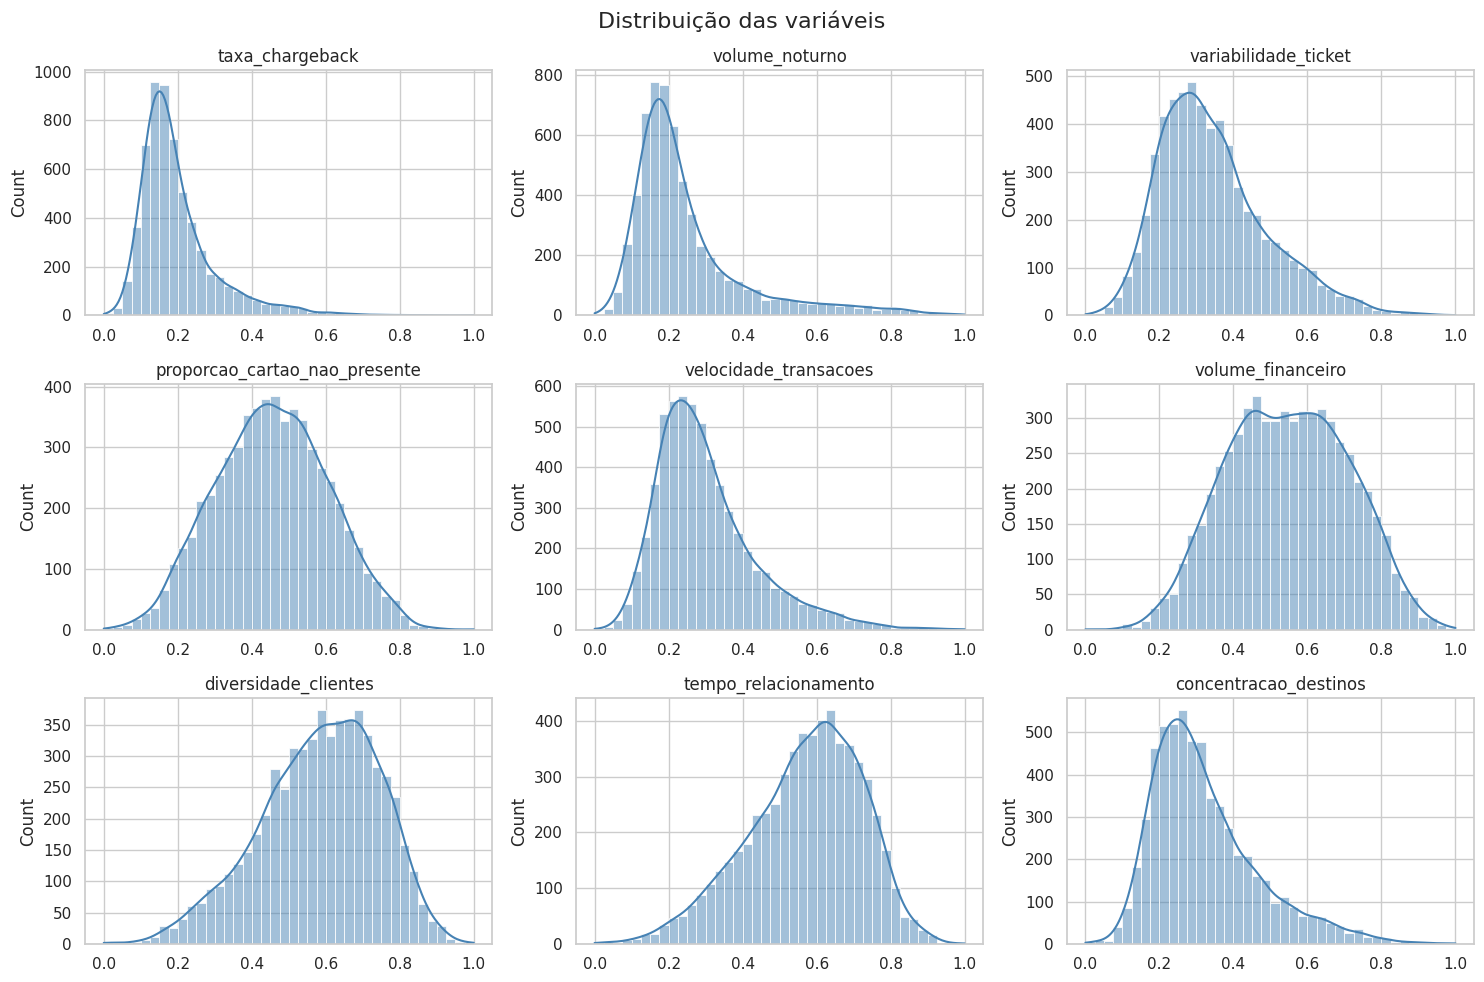

In [ ]:
# Um histograma para cada variável numérica (grade 3 x 3)
fig, eixos = plt.subplots(3, 3, figsize=(15, 10))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    sns.histplot(df[coluna], bins=40, kde=True, ax=eixo, color="steelblue")
    eixo.set_title(coluna)
    eixo.set_xlabel("")

plt.suptitle("Distribuição das variáveis", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Assimetria (skewness): 0 = simétrica; > 0 = cauda longa à direita; < 0 = cauda à esquerda
df[colunas_numericas].skew().sort_values(ascending=False).to_frame("assimetria")

,assimetria
taxa_chargeback,1.936
volume_noturno,1.918
velocidade_transacoes,1.224
concentracao_destinos,1.095
variabilidade_ticket,0.852
proporcao_cartao_nao_presente,0.023
volume_financeiro,0.003
diversidade_clientes,-0.424
tempo_relacionamento,-0.487


**Interpretação:**

* `taxa_chargeback`, `volume_noturno`, `velocidade_transacoes` e `concentracao_destinos` têm **cauda longa à direita**: a maioria das entidades tem valores baixos, mas existe um **pequeno grupo com valores muito altos**. Esse é exatamente o comportamento esperado de fraude: **rara e extrema**.
* `diversidade_clientes` e `tempo_relacionamento` têm leve cauda à esquerda (poucas entidades com valores muito baixos — contas novas e com poucos clientes).

### 3.4 Outliers (boxplot e regra do IQR)

A regra do **IQR** (intervalo interquartil) considera outlier todo valor abaixo de `Q1 − 1,5·IQR` ou acima de `Q3 + 1,5·IQR`.

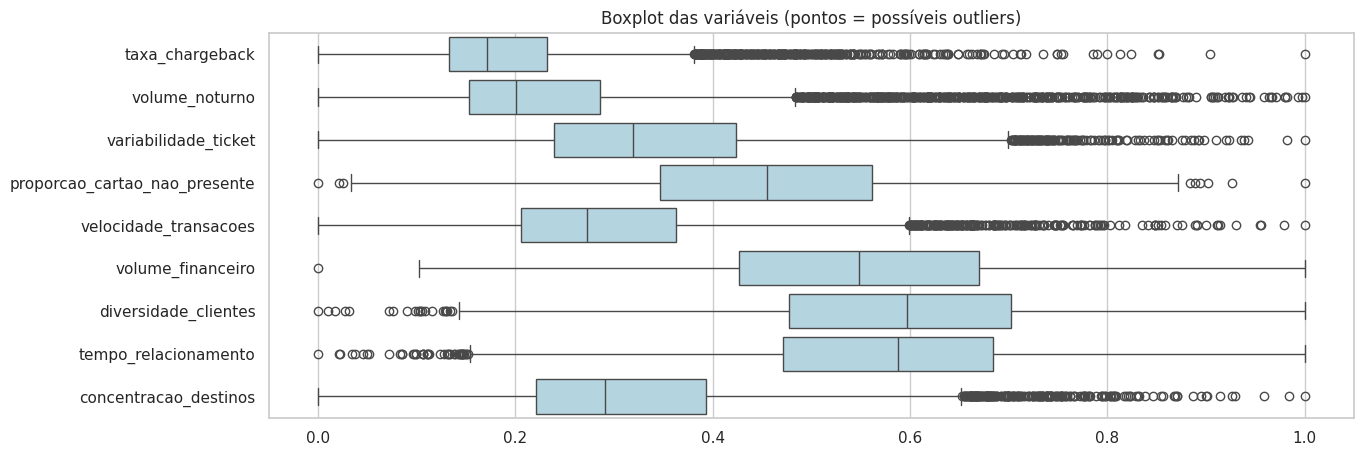

Outliers por variável:
taxa_chargeback                  399
volume_noturno                   567
variabilidade_ticket             143
proporcao_cartao_nao_presente      9
velocidade_transacoes            247
volume_financeiro                  1
diversidade_clientes              21
tempo_relacionamento              44
concentracao_destinos            210
dtype: int64

Entidades com pelo menos 1 outlier: 589 (9.8% da base)


In [ ]:
# Boxplot de todas as variáveis lado a lado
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[colunas_numericas], orient="h", color="lightblue")
plt.title("Boxplot das variáveis (pontos = possíveis outliers)")
plt.show()

# Regra do IQR
Q1 = df[colunas_numericas].quantile(0.25)
Q3 = df[colunas_numericas].quantile(0.75)
IQR = Q3 - Q1
eh_outlier = (df[colunas_numericas] < Q1 - 1.5 * IQR) | (df[colunas_numericas] > Q3 + 1.5 * IQR)

print("Outliers por variável:")
print(eh_outlier.sum())
print("\nEntidades com pelo menos 1 outlier:", eh_outlier.any(axis=1).sum(),
      f"({eh_outlier.any(axis=1).mean():.1%} da base)")

Cerca de **10% das entidades** possuem algum valor extremo, principalmente em `volume_noturno` e `taxa_chargeback`.

> 💡 **Observção:** em detecção de fraude, **outliers não são erro de digitação — eles podem ser justamente as fraudes!** Por isso **não serão removidos** esses pontos. Será utilizado algoritmos capazes de identificá-los (DBSCAN, GMM e SOM).

### 3.5 Correlação entre variáveis

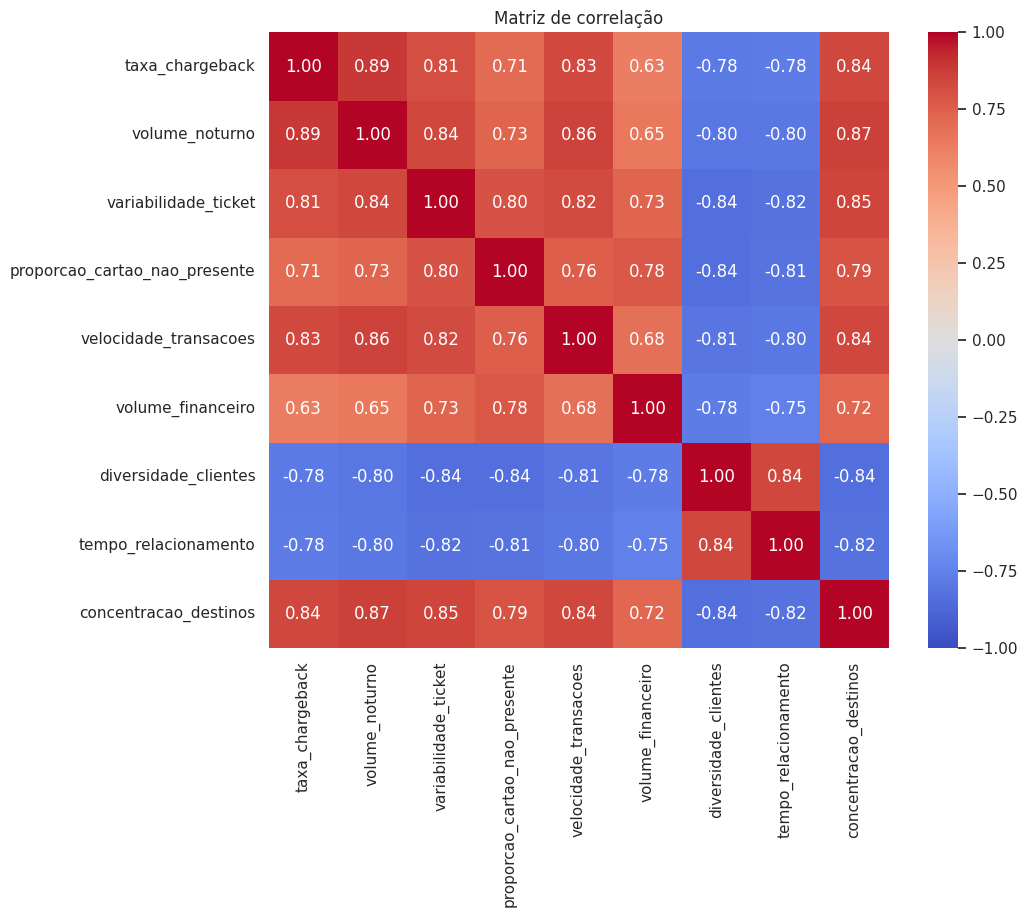

In [ ]:
# Matriz de correlação de Pearson
correlacao = df[colunas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação")
plt.show()

**Característica marcante da base 05:**

* Todas as variáveis de risco são **fortemente correlacionadas entre si** (0,6 a 0,9).
* `diversidade_clientes` e `tempo_relacionamento` têm **correlação negativa forte** com as demais.

Ou seja, as 9 variáveis “contam a mesma história”: existe **um único eixo de risco** que vai de *“entidade antiga, com muitos clientes e pouco chargeback”* até *“entidade nova, concentrada, noturna e com muito chargeback”*. É daí que vem a ideia do **“mapa de risco”**: os dados formam um **gradiente contínuo**, e não grupos totalmente separados.

Essa observação vai guiar a escolha dos algoritmos (seção 6).

---
## 4. Pré-processamento

| Problema | Situação na base | Decisão |
|---|---|---|
| Dados ausentes | não há | nada a fazer |
| Duplicados | não há | nada a fazer |
| Coluna identificadora | `id_entidade` | retirar do modelo (não é comportamento) |
| Coluna categórica | `tipo_entidade` não diferencia os grupos | retirar do modelo, usar só na análise final |
| Escala | já está em [0,1] (Min-Max), mas os desvios são diferentes | aplicar **padronização z-score** |
| Outliers | ~10% das entidades | **manter** (podem ser fraudes) |

**Por que padronizar se já está entre 0 e 1?** Algoritmos baseados em **distância euclidiana** (K-Means, DBSCAN, SOM) dão mais peso às variáveis com maior variação. Com o **z-score** (`(x − média) / desvio`), todas as variáveis passam a ter média 0 e desvio 1, contribuindo igualmente para a distância.

In [ ]:
# Matriz X apenas com as variáveis numéricas
X = df[colunas_numericas].values

# Padronização z-score
scaler = StandardScaler()
X_pad = scaler.fit_transform(X)

# Conferência: médias ~0 e desvios ~1
print("Médias após padronizar:", X_pad.mean(axis=0).round(2))
print("Desvios após padronizar:", X_pad.std(axis=0).round(2))

Médias após padronizar: [ 0.  0. -0. -0.  0. -0. -0. -0. -0.]
Desvios após padronizar: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## 5. Redução de dimensionalidade com PCA

Não é possivel desenhar 9 dimensões. A **PCA (Análise de Componentes Principais)** cria novas variáveis (componentes) que resumem a maior parte da informação. Assim será possivel visualizar a base em **2D**.

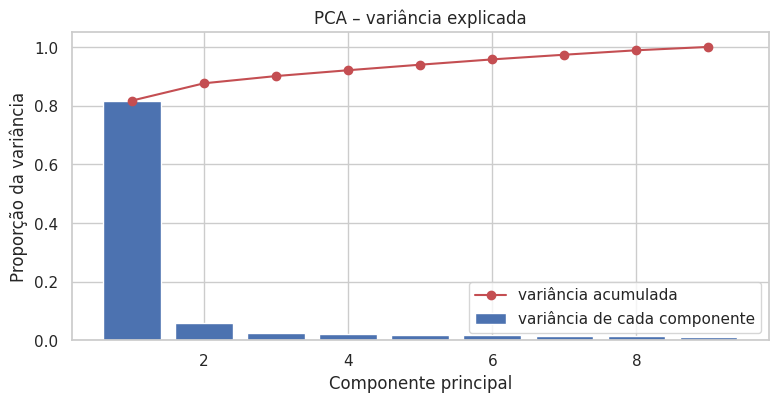

PC1: 81.7%
PC2: 5.9%
PC3: 2.5%


In [ ]:
# Ajusta a PCA com todos os componentes para ver quanta variância cada um explica
pca_completa = PCA(random_state=SEED).fit(X_pad)
variancia = pca_completa.explained_variance_ratio_

plt.figure(figsize=(9, 4))
plt.bar(range(1, 10), variancia, label="variância de cada componente")
plt.plot(range(1, 10), variancia.cumsum(), "o-r", label="variância acumulada")
plt.xlabel("Componente principal")
plt.ylabel("Proporção da variância")
plt.title("PCA – variância explicada")
plt.legend()
plt.show()

for i, v in enumerate(variancia[:3], start=1):
    print(f"PC{i}: {v:.1%}")

A análise de componentes principais revelou que o primeiro componente explica 81,7% da variância total, e os dois primeiros juntos explicam 87,6%. Isso indica alta redundância entre as variáveis e a presença de um eixo dominante de risco, o que justifica a projeção bidimensional (PC1 × PC2) usada na visualização dos agrupamentos.

                                 PC1    PC2
diversidade_clientes          -0.342 -0.175
tempo_relacionamento          -0.337 -0.135
volume_financeiro              0.304  0.625
proporcao_cartao_nao_presente  0.327  0.375
taxa_chargeback                0.330 -0.433
velocidade_transacoes          0.336 -0.237
volume_noturno                 0.338 -0.394
variabilidade_ticket           0.341 -0.047
concentracao_destinos          0.344 -0.135


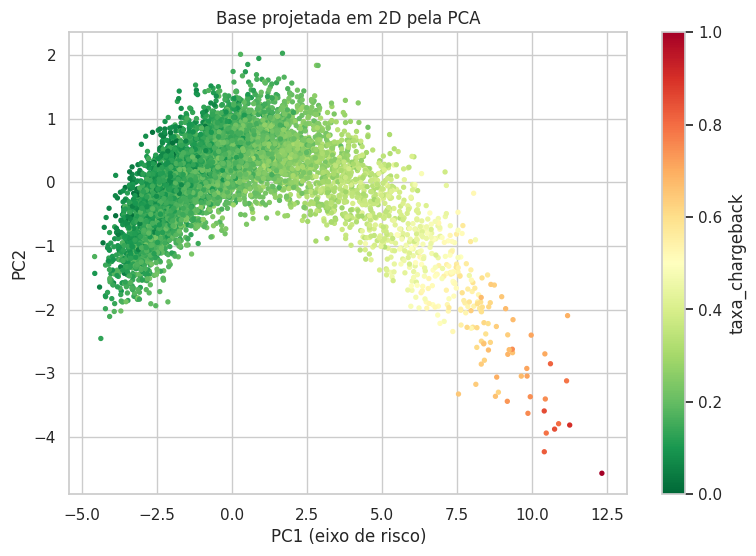

In [ ]:
# PCA com 2 componentes, usada em TODOS os gráficos daqui para frente
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_pad)

# Quais variáveis "formam" o 1º componente? (cargas / loadings)
cargas = pd.DataFrame(pca.components_.T, index=colunas_numericas, columns=["PC1", "PC2"])
print(cargas.sort_values("PC1"))

# Gráfico de dispersão 2D colorido pela taxa de chargeback
plt.figure(figsize=(9, 6))
pontos = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["taxa_chargeback"], cmap="RdYlGn_r", s=8)
plt.colorbar(pontos, label="taxa_chargeback")
plt.xlabel("PC1 (eixo de risco)")
plt.ylabel("PC2")
plt.title("Base projetada em 2D pela PCA")
plt.show()

**Interpretação da PCA:**

* O **PC1 sozinho explica ~82% da variância** — confirma que existe **um eixo principal de risco**.
* No PC1, as variáveis de risco têm carga **positiva** e `diversidade_clientes`/`tempo_relacionamento` têm carga **negativa**. Portanto: **quanto mais à direita no gráfico, maior o risco**.
* A nuvem de pontos é **contínua** (sem grupos separadas), tem formato de **arco curvo** e uma **cauda à direita** com poucos pontos muito fora do perfil. Esse formato curvo é um ponto de atenção para algoritmos que supõem grupos esféricos (K-Means).

---
## 6. Justificativa metodológica (escolha dos algoritmos)

O diagnóstico da EDA (Análise exploratoria dos dados) mostrou três características que guiam a escolha:

1. **Estrutura contínua** (um gradiente de risco, sem grupos bem separados);
2. **Cauda de pontos extremos** (prováveis fraudes, ~2 a 10% da base);
3. **Variáveis numéricas, contínuas e muito correlacionadas.**

| Algoritmo | Família | Por que faz sentido nesta base | Limitação esperada |
|---|---|---|---|
| **K-Means** | Particional | Linha de base simples e rápida; segmenta o gradiente em faixas (baixo/médio/alto risco) | Supõe grupos esféricos e é sensível a outliers; todo ponto é forçado a um grupo |
| **GMM** | Probabilístico (EM) | Os grupos se sobrepõem no gradiente → o GMM dá **probabilidade de pertencer** a cada perfil e permite elipses (covariância). A **verossimilhança baixa** indica pontos atípicos | Precisa escolher K (usamos BIC/AIC) |
| **DBSCAN** | Densidade | Rotula **ruído de forma nativa**: pontos em regiões pouco densas = candidatos a fraude. Não exige K | Sensível à escolha de `eps`; não lida bem com densidades diferentes |
| **SOM (Kohonen)** | Rede neural | Ideal para **dados contínuos**: preserva a topologia e gera um **mapa 2D de risco** interpretável (U-Matrix e mapas de componentes) | Mais hiperparâmetros (grade, taxa, raio) |

Os quatro métodos olham os dados de **formas diferentes** (centroides, probabilidade, densidade e topologia). Se eles **concordarem** sobre quem é de alto risco, temos mais confiança nas conclusões.

**Métricas de validação interna** (não há rótulos):

* **Silhueta** ∈ [−1, 1] → quanto **maior**, melhor (coesão × separação);
* **Davies-Bouldin** → quanto **menor**, melhor;
* **Índice de Dunn** → quanto **maior**, melhor (menor distância entre grupos ÷ maior diâmetro de um grupo);
* **BIC/AIC** (GMM) → quanto **menor**, melhor;
* **Erro de quantização e erro topográfico** (SOM) → quanto **menores**, melhor.

In [ ]:
# ---------- Funções auxiliares usadas em várias seções ----------

def ordenar_por_risco(rotulos, referencia=df["taxa_chargeback"].values):
    # Renumera os grupos para que 0 = menor risco e o último = maior risco.
    # Usa a média da taxa de chargeback de cada grupo como critério, pois chargeback é o indicador mais direto de fraude no setor de pagamentos.
    # O rótulo -1 (ruído do DBSCAN) é mantido como -1.
    rotulos = np.asarray(rotulos)
    grupos = [g for g in np.unique(rotulos) if g != -1]
    medias = {g: referencia[rotulos == g].mean() for g in grupos}
    ordem = sorted(grupos, key=lambda g: medias[g])
    mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
    mapa[-1] = -1
    return np.array([mapa[r] for r in rotulos])


def indice_dunn(X_usado, rotulos):
    # Índice de Dunn = menor distância entre pontos de grupos diferentes
    # ÷ maior distância entre dois pontos do mesmo grupo (diâmetro).
    # Quanto MAIOR, melhor: grupos compactos (diâmetro pequeno) e bem separados.
    grupos = np.unique(rotulos)
    # Maior diâmetro entre todos os grupos
    maior_diametro = max(pdist(X_usado[rotulos == g]).max() for g in grupos)
    # Menor distância entre dois pontos de grupos diferentes
    menor_separacao = min(cdist(X_usado[rotulos == a], X_usado[rotulos == b]).min()
                          for i, a in enumerate(grupos) for b in grupos[i + 1:])
    return menor_separacao / maior_diametro


def metricas(X_usado, rotulos, nome):
    # Calcula as métricas internas de validação para um agrupamento.
    # Pontos de ruído (-1) são ignorados no cálculo.
    mascara = rotulos != -1
    return {
        "modelo": nome,
        "n_grupos": len(set(rotulos[mascara])),
        "silhueta": silhouette_score(X_usado[mascara], rotulos[mascara]),
        "davies_bouldin": davies_bouldin_score(X_usado[mascara], rotulos[mascara]),
        "dunn": indice_dunn(X_usado[mascara], rotulos[mascara]),
    }


def grafico_pca(rotulos, titulo, nomes=None):
    # Desenha os pontos no plano da PCA, coloridos pelo grupo.
    plt.figure(figsize=(9, 6))
    for g in np.unique(rotulos):
        m = rotulos == g
        rotulo = nomes.get(g, g) if nomes else g
        if g == -1:
            plt.scatter(X_pca[m, 0], X_pca[m, 1], c="black", marker="x", s=25, label=f"ruído ({m.sum()})")
        else:
            cor = CORES_RISCO.get(g, None) if nomes == NOMES_RISCO else "lightgray"
            plt.scatter(X_pca[m, 0], X_pca[m, 1], s=8, alpha=0.6, color=cor, label=f"{rotulo} ({m.sum()})")
    plt.xlabel("PC1 (eixo de risco)")
    plt.ylabel("PC2")
    plt.title(titulo)
    plt.legend(markerscale=2)
    plt.show()


NOMES_RISCO = {0: "Baixo risco", 1: "Médio risco", 2: "Alto risco"}
CORES_RISCO = {0: "tab:green", 1: "tab:orange", 2: "tab:red"}   # verde, laranja, vermelho
resultados = []   # lista onde guardaremos as métricas de cada modelo

---
## 7. Algoritmo 1 – K-Means (particional)

O K-Means escolhe **K centroides** e coloca cada ponto no grupo do centroide mais próximo, repetindo até estabilizar.

### 7.1 Ajuste do hiperparâmetro K (cotovelo + silhueta + Davies-Bouldin)

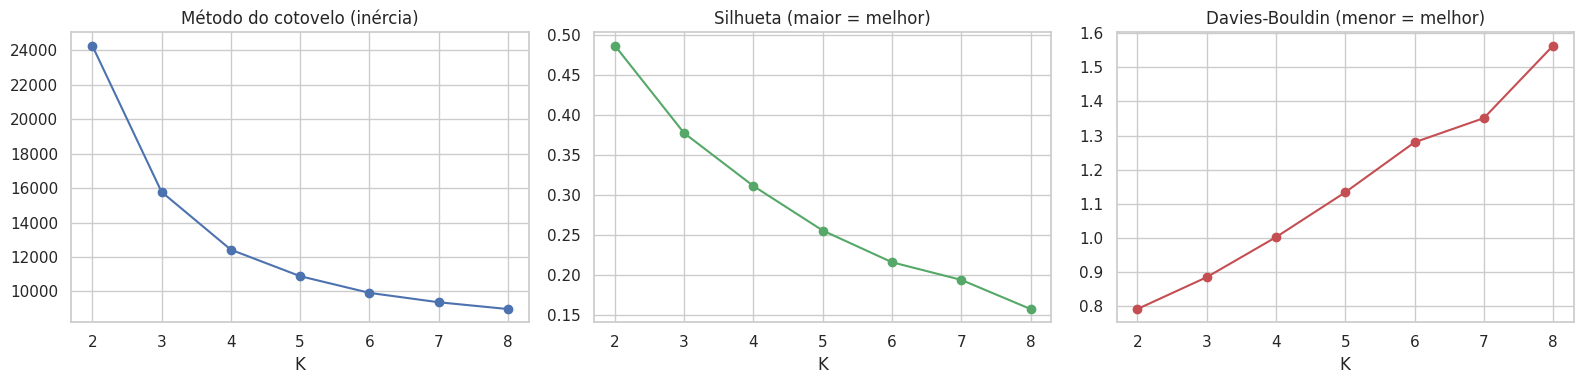

,K,inercia,silhueta,davies_bouldin
0,2,24276.782,0.487,0.791
1,3,15777.495,0.378,0.885
2,4,12421.593,0.311,1.002
3,5,10884.674,0.256,1.134
4,6,9915.216,0.216,1.280
5,7,9369.864,0.194,1.351
6,8,8975.226,0.157,1.564


In [ ]:
valores_k = range(2, 9)
inercias, silhuetas, dbs = [], [], []

for k in valores_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    rotulos = modelo.fit_predict(X_pad)
    inercias.append(modelo.inertia_)                    # soma das distâncias ao centroide (cotovelo)
    silhuetas.append(silhouette_score(X_pad, rotulos))  # maior = melhor
    dbs.append(davies_bouldin_score(X_pad, rotulos))    # menor = melhor

fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
eixos[0].plot(valores_k, inercias, "o-");  eixos[0].set_title("Método do cotovelo (inércia)")
eixos[1].plot(valores_k, silhuetas, "o-g"); eixos[1].set_title("Silhueta (maior = melhor)")
eixos[2].plot(valores_k, dbs, "o-r");      eixos[2].set_title("Davies-Bouldin (menor = melhor)")
for e in eixos:
    e.set_xlabel("K")
plt.tight_layout()
plt.show()

pd.DataFrame({"K": list(valores_k), "inercia": inercias, "silhueta": silhuetas, "davies_bouldin": dbs})

**Escolha do K**

* **Método do cotovelo (inércia):** a inércia cai de forma expressiva até K = 3 e, a partir daí, as quedas ficam cada vez menores:

| Passagem | Queda da inércia |
|---|---|
| K = 2 → 3 | ≈ 8.500 (35%) |
| K = 3 → 4 | ≈ 3.360 (21%) |
| K = 4 → 5 | ≈ 1.540 (12%) |
| K = 5 → 6 | ≈ 970 (9%) |

  A redução de K = 3 para K = 4 é **menos da metade** da obtida de K = 2 para K = 3. Ou seja, até K = 3 cada grupo novo melhora bastante o agrupamento; depois disso, o ganho é pequeno. O **cotovelo está em torno de K = 3**. Como a curva desce de forma suave (sem uma quebra brusca), isso também mostra que **não existem grupos naturalmente separados**, o que é coerente com o gradiente contínuo visto na EDA.

* **Silhueta e Davies-Bouldin** favorecem **K = 2**. Isso é típico de dados com estrutura contínua: a forma mais "fácil" de cortar um gradiente é ao meio. Ainda assim, **K = 3 é o segundo melhor** nessas métricas, com valores aceitáveis.

* **Contexto do negócio:** para uma operadora de pagamentos, **3 faixas (baixo / médio / alto risco)** são mais úteis do que só 2, pois permitem tratar de forma diferente os casos intermediários.

➡️ **Escolha: K = 3**, apoiada pelo **cotovelo**, pelo **contexto do negócio**.


Baixo risco    2892
Médio risco    2319
Alto risco      789
Name: count, dtype: int64


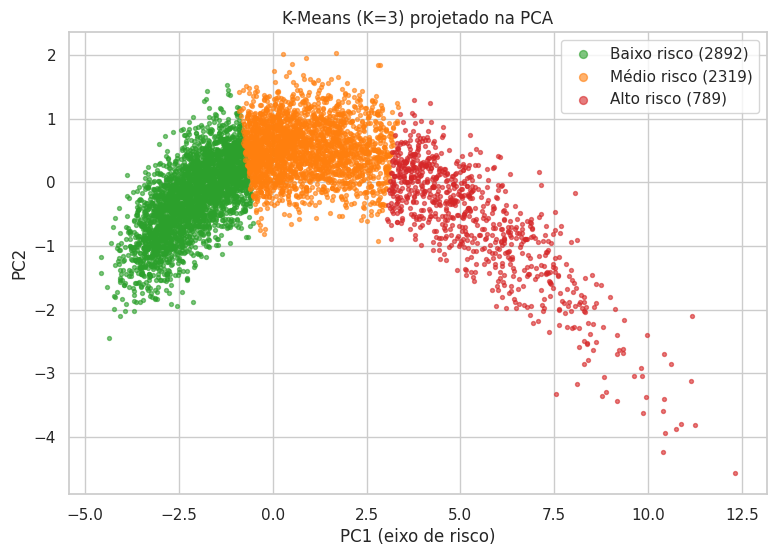

In [ ]:
# Modelo final do K-Means com K = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED)
rotulos_kmeans = ordenar_por_risco(kmeans.fit_predict(X_pad))   # 0 = baixo, 2 = alto risco
df["grupo_kmeans"] = rotulos_kmeans

resultados.append(metricas(X_pad, rotulos_kmeans, "K-Means (K=3)"))
print(pd.Series(rotulos_kmeans).map(NOMES_RISCO).value_counts())

grafico_pca(rotulos_kmeans, "K-Means (K=3) projetado na PCA", NOMES_RISCO)

**Como os grupos viraram "baixo", "médio" e "alto" risco?**

O K-Means **não sabe o que é risco**: ele apenas separa as entidades em 3 grupos de comportamento parecido e devolve números (0, 1 e 2) **sem significado**. A ordem desses números é aleatória e pode mudar a cada execução.

Para dar significado aos grupos, a função `ordenar_por_risco` faz três passos:

1. calcula a **taxa média de chargeback** de cada grupo;
2. ordena os grupos da menor média para a maior;
3. renumera: **0 = menor chargeback**, **1 = intermediário** e **2 = maior chargeback**.

| Grupo | Chargeback médio | Rótulo | Nome |
|---|---|---|---|
| menor média | 0,136 | 0 | Baixo risco |
| intermediário | 0,204 | 1 | Médio risco |
| maior média | 0,410 | 2 | Alto risco |

Depois, o dicionário `NOMES_RISCO` traduz os números em nomes, usados nas legendas e nas cores dos gráficos (verde, laranja e vermelho).


**Resultado:** cerca de **2.892** entidades de baixo risco, **2.319** de médio risco e **789** de alto risco (~13% da base).

In [ ]:
# Perfil médio de cada grupo (nas variáveis originais, de 0 a 1)
perfil_kmeans = df.groupby("grupo_kmeans")[colunas_numericas].mean().T
perfil_kmeans.columns = [NOMES_RISCO[c] for c in perfil_kmeans.columns]
perfil_kmeans

,Baixo risco,Médio risco,Alto risco
taxa_chargeback,0.136,0.204,0.410
volume_noturno,0.157,0.253,0.594
variabilidade_ticket,0.239,0.388,0.610
proporcao_cartao_nao_presente,0.336,0.527,0.681
velocidade_transacoes,0.211,0.325,0.559
volume_financeiro,0.419,0.636,0.762
diversidade_clientes,0.709,0.519,0.315
tempo_relacionamento,0.686,0.512,0.310
concentracao_destinos,0.222,0.356,0.595


In [ ]:
# Estabilidade: foi rodado o K-Means com 5 sementes diferentes e foi comparado com o resultado principal.
# ARI = 1 significa que os grupos são idênticos.
for semente in [1, 7, 21, 99, 123]:
    outro = KMeans(n_clusters=3, n_init=10, random_state=semente).fit_predict(X_pad)
    print(f"semente {semente:>3}: ARI = {adjusted_rand_score(rotulos_kmeans, outro):.3f}")

semente   1: ARI = 1.000
semente   7: ARI = 0.989
semente  21: ARI = 0.996
semente  99: ARI = 1.000
semente 123: ARI = 1.000


**Leitura do K-Means:** os três grupos são **faixas ao longo do PC1**. O grupo de **alto risco** tem chargeback, volume noturno, velocidade e concentração muito maiores, além de **menor tempo de relacionamento e menor diversidade de clientes**. O ARI ≈ 1 mostra que o resultado é **estável**.

*Limitação:* o K-Means **obriga todo ponto a pertencer a um grupo** e não diz “quão certo” está — os pontos na fronteira entre médio e alto risco recebem o mesmo tratamento que os pontos no centro do grupo. O GMM resolve isso.

---
## 8. Algoritmo 2 – GMM (Modelo de Mistura de Gaussianas)

O GMM supõe que os dados vêm de uma **mistura de K distribuições normais (gaussianas)**. Ele é treinado pelo algoritmo **EM (Expectativa–Maximização)** e devolve, para cada ponto, a **probabilidade** de pertencer a cada grupo.

### 8.1 Ajuste de hiperparâmetros: número de componentes e tipo de covariância (BIC/AIC)

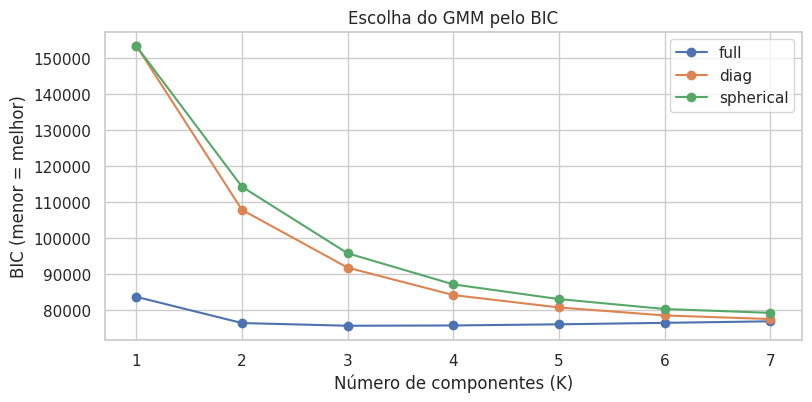

,covariancia,K,BIC,AIC
2,full,3,75718.102,74619.382
3,full,4,75794.222,74327.028
4,full,5,76117.403,74281.736
1,full,2,76470.178,75739.931
5,full,6,76523.570,74319.430


In [ ]:
tipos_cov = ["full", "diag", "spherical"]     # formatos possíveis das elipses
lista = []

for tipo in tipos_cov:
    for k in range(1, 8):
        gmm_teste = GaussianMixture(n_components=k, covariance_type=tipo, n_init=3, random_state=SEED)
        gmm_teste.fit(X_pad)
        lista.append({"covariancia": tipo, "K": k,
                      "BIC": gmm_teste.bic(X_pad), "AIC": gmm_teste.aic(X_pad)})

tabela_gmm = pd.DataFrame(lista)

# Gráfico do BIC para cada tipo de covariância
plt.figure(figsize=(9, 4))
for tipo in tipos_cov:
    parte = tabela_gmm[tabela_gmm["covariancia"] == tipo]
    plt.plot(parte["K"], parte["BIC"], "o-", label=tipo)
plt.xlabel("Número de componentes (K)")
plt.ylabel("BIC (menor = melhor)")
plt.title("Escolha do GMM pelo BIC")
plt.legend()
plt.show()

# Melhor combinação
tabela_gmm.sort_values("BIC").head(5)

O **menor BIC** é obtido com **covariância `full` e K = 3**. O BIC penaliza modelos complexos, então esse resultado é uma **evidência estatística independente** de que **3 perfis** descrevem bem a base — o mesmo K que escolhemos para o K-Means pelo contexto do negócio e metodo do cotovelo.

Baixo risco    2909
Médio risco    2282
Alto risco      809
Name: count, dtype: int64


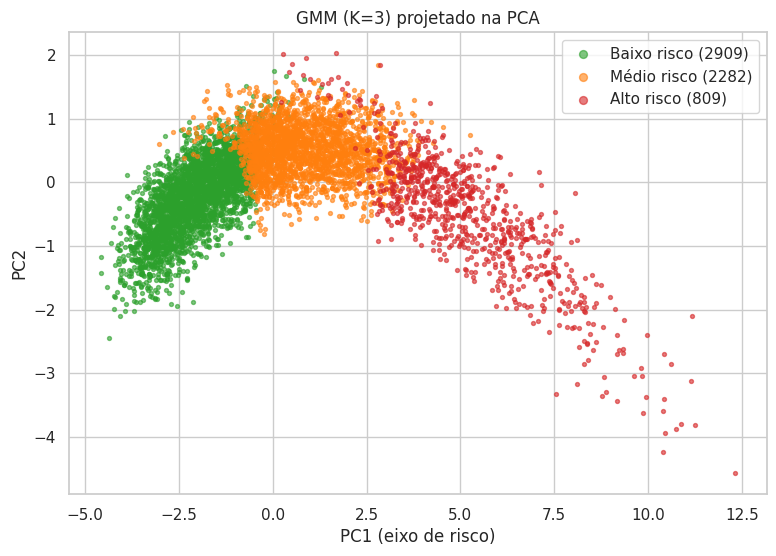

In [ ]:
# Modelo final do GMM
gmm = GaussianMixture(n_components=3, covariance_type="full", n_init=5, random_state=SEED)
gmm.fit(X_pad)

rotulos_gmm = ordenar_por_risco(gmm.predict(X_pad))
df["grupo_gmm"] = rotulos_gmm

# Probabilidade do grupo escolhido (o "grau de certeza" do modelo)
df["prob_gmm"] = gmm.predict_proba(X_pad).max(axis=1)

resultados.append(metricas(X_pad, rotulos_gmm, "GMM (K=3, full)"))
print(pd.Series(rotulos_gmm).map(NOMES_RISCO).value_counts())

grafico_pca(rotulos_gmm, "GMM (K=3) projetado na PCA", NOMES_RISCO)

Entidades na zona de incerteza: 997 (16.6%)


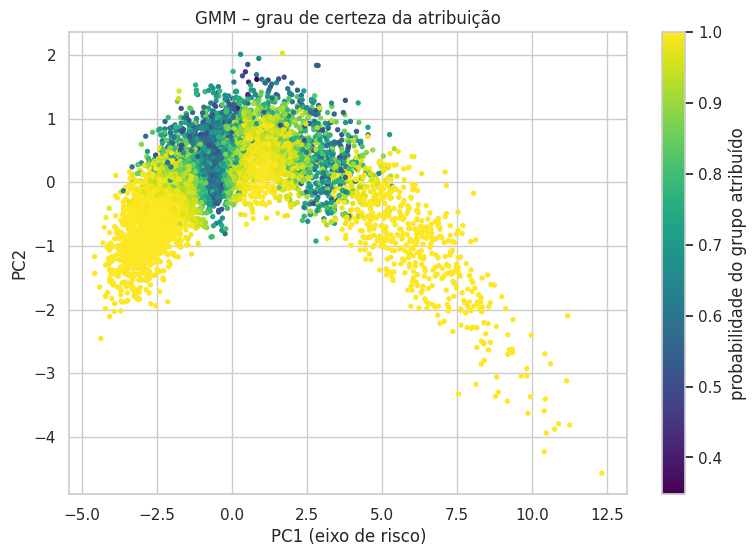

In [ ]:
# Pontos com probabilidade < 70%: o modelo está "em dúvida" entre dois perfis
incertos = df["prob_gmm"] < 0.70
print(f"Entidades na zona de incerteza: {incertos.sum()} ({incertos.mean():.1%})")

plt.figure(figsize=(9, 6))
pontos = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["prob_gmm"], cmap="viridis", s=8)
plt.colorbar(pontos, label="probabilidade do grupo atribuído")
plt.xlabel("PC1 (eixo de risco)"); plt.ylabel("PC2")
plt.title("GMM – grau de certeza da atribuição")
plt.show()

### 8.2 Detecção de anomalias com o GMM

Cada ponto recebe uma **log-verossimilhança** (`score_samples`): quanto **menor**, mais “estranho” é o ponto para o modelo. Marcamos como anomalia os **2% menos prováveis**.

Anomalias pelo GMM: 120


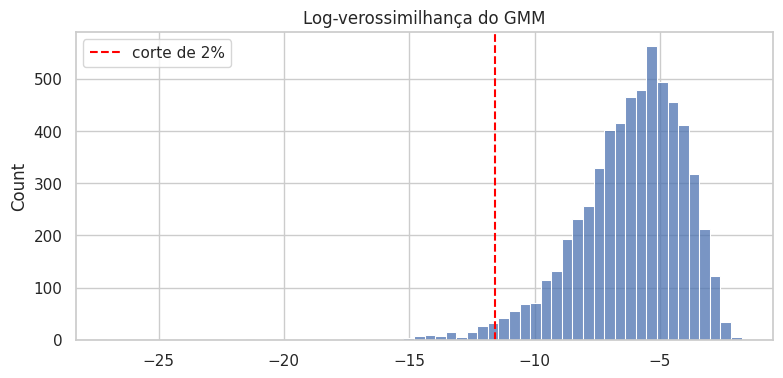

anomalia_gmm,normal,anomalia
taxa_chargeback,0.196,0.339
volume_noturno,0.248,0.428
variabilidade_ticket,0.343,0.483
proporcao_cartao_nao_presente,0.454,0.540
velocidade_transacoes,0.298,0.450
volume_financeiro,0.547,0.603
diversidade_clientes,0.586,0.459
tempo_relacionamento,0.572,0.434
concentracao_destinos,0.320,0.461


In [ ]:
log_veross = gmm.score_samples(X_pad)        # log-verossimilhança de cada entidade
limite = np.percentile(log_veross, 2)         # corte nos 2% menores
df["anomalia_gmm"] = log_veross < limite

print("Anomalias pelo GMM:", df["anomalia_gmm"].sum())

plt.figure(figsize=(9, 4))
sns.histplot(log_veross, bins=60)
plt.axvline(limite, color="red", linestyle="--", label="corte de 2%")
plt.title("Log-verossimilhança do GMM")
plt.legend()
plt.show()

# Perfil médio: anomalias x restante
df.groupby("anomalia_gmm")[colunas_numericas].mean().T.rename(columns={False: "normal", True: "anomalia"})

**Leitura do GMM:**

* Os grupos ficam muito parecidos com os do K-Means, mas agora é usada a **probabilidade** de cada atribuição. As entidades com baixa certeza estão nas **fronteiras** entre perfis (o gradiente contínuo).
* As **anomalias** do GMM têm, em média, chargeback, volume noturno e concentração **bem mais altos** e tempo de relacionamento **mais baixo** que o restante. É possivel reparar que o GMM também marca pontos com **combinações incomuns** de variáveis (fora do eixo principal), e não só os mais extremos — por isso ele complementa o DBSCAN.

---
## 9. Algoritmo 3 – DBSCAN (baseado em densidade)

O DBSCAN agrupa pontos que estão em **regiões densas** e marca como **ruído (−1)** os pontos isolados. Ele tem dois hiperparâmetros:

* **`min_samples`**: mínimo de vizinhos para um ponto ser “núcleo”. Regra prática: `2 × número de variáveis` = 2 × 9 = **18**;
* **`eps`**: raio da vizinhança. Escolhido pelo **gráfico de k-distância** (procura-se o “joelho” da curva).

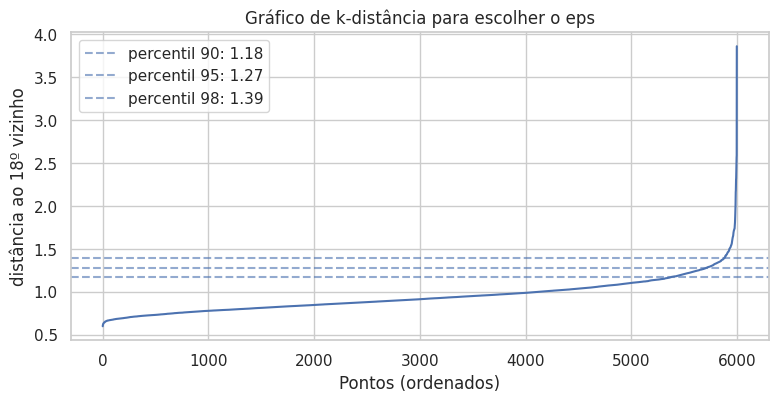

In [ ]:
min_samples = 2 * X_pad.shape[1]     # 2 x 9 variáveis = 18

# Distância de cada ponto até o seu 18º vizinho mais próximo
vizinhos = NearestNeighbors(n_neighbors=min_samples).fit(X_pad)
distancias, _ = vizinhos.kneighbors(X_pad)
k_dist = np.sort(distancias[:, -1])  # ordena da menor para a maior

plt.figure(figsize=(9, 4))
plt.plot(k_dist)
for p in [90, 95, 98]:
    plt.axhline(np.percentile(k_dist, p), linestyle="--", alpha=0.6, label=f"percentil {p}: {np.percentile(k_dist, p):.2f}")
plt.xlabel("Pontos (ordenados)")
plt.ylabel(f"distância ao {min_samples}º vizinho")
plt.title("Gráfico de k-distância para escolher o eps")
plt.legend()
plt.show()

In [ ]:
# Testamos alguns valores de eps ao redor do "joelho"
for eps in [0.9, 1.0, 1.1, 1.2, 1.3, 1.5]:
    r = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pad)
    n_grupos = len(set(r)) - (1 if -1 in r else 0)
    print(f"eps={eps:.1f} -> grupos: {n_grupos} | ruído: {(r == -1).sum():>4} ({(r == -1).mean():.1%})")

eps=0.9 -> grupos: 4 | ruído: 1020 (17.0%)
eps=1.0 -> grupos: 1 | ruído:  391 (6.5%)
eps=1.1 -> grupos: 1 | ruído:  138 (2.3%)
eps=1.2 -> grupos: 1 | ruído:   60 (1.0%)
eps=1.3 -> grupos: 1 | ruído:   33 (0.5%)
eps=1.5 -> grupos: 1 | ruído:   16 (0.3%)


**Resultado muito informativo:** com `eps` pequeno (0,9) o DBSCAN apenas “quebra” a nuvem em pedaços e marca muito ruído (~17%); a partir de `eps = 1,0` ele encontra **apenas 1 grupo denso** + pontos de ruído. Isso **confirma o diagnóstico da EDA**: a base é **uma única nuvem contínua**, sem regiões densas separadas.

Por isso usamos o DBSCAN com o papel em que ele é melhor: **detector de ruído**. Escolhemos `eps = 1.2` (próximo ao percentil 95–98 da k-distância), que marca cerca de **1% da base** como ruído — os pontos mais isolados.

Pontos de ruído: 60


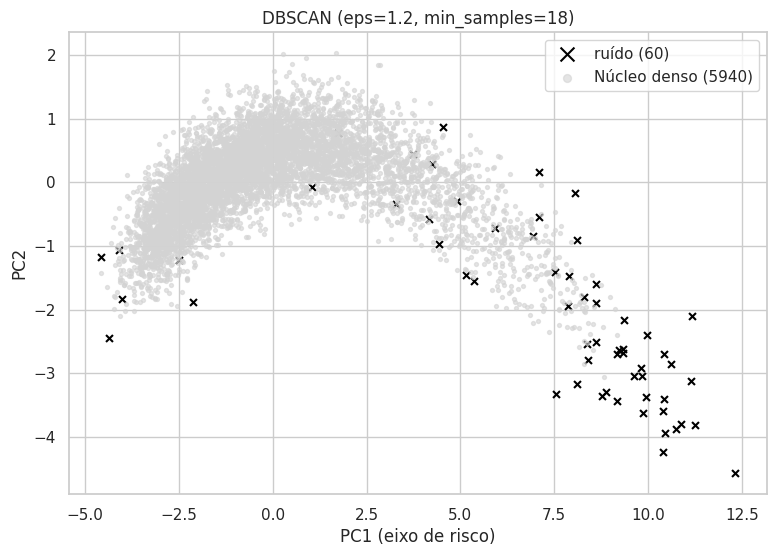

grupo_gmm     Alto risco  Baixo risco  Médio risco
ruido_dbscan                                      
False                759         2903         2278
True                  50            6            4


In [ ]:
dbscan = DBSCAN(eps=1.2, min_samples=min_samples)
rotulos_dbscan = dbscan.fit_predict(X_pad)
df["ruido_dbscan"] = rotulos_dbscan == -1

print("Pontos de ruído:", df["ruido_dbscan"].sum())
grafico_pca(rotulos_dbscan, "DBSCAN (eps=1.2, min_samples=18)", {0: "Núcleo denso"})

# Onde estão os ruídos? Comparação com o grupo de risco do GMM
print(pd.crosstab(df["ruido_dbscan"], df["grupo_gmm"].map(NOMES_RISCO)))

In [ ]:
# Perfil médio: ruído x núcleo denso
df.groupby("ruido_dbscan")[colunas_numericas].mean().T.rename(columns={False: "núcleo", True: "ruído"})

ruido_dbscan,núcleo,ruído
taxa_chargeback,0.195,0.563
volume_noturno,0.247,0.731
variabilidade_ticket,0.342,0.696
proporcao_cartao_nao_presente,0.453,0.683
velocidade_transacoes,0.297,0.686
volume_financeiro,0.547,0.690
diversidade_clientes,0.587,0.262
tempo_relacionamento,0.572,0.249
concentracao_destinos,0.319,0.687


**Leitura do DBSCAN:** quase todos os pontos de ruído estão no grupo de **alto risco** e ficam na **ponta direita** do PC1. São entidades com comportamento **tão extremo** que não têm vizinhos parecidos — **os principais candidatos a fraude**.

> Como o DBSCAN gera só 1 grupo, a silhueta não pode ser calculada para ele (ela exige pelo menos 2 grupos). Sua avaliação é feita pela **concordância** com as anomalias dos outros métodos (seção 11).

---
## 10. Algoritmo 4 – SOM / Mapa Auto-Organizável de Kohonen

O SOM é uma **rede neural** com uma **grade 2D de neurônios**. Cada neurônio tem um vetor de pesos com a mesma dimensão dos dados (9). No treinamento:

1. Sorteia-se uma entidade `x`;
2. Encontra-se o neurônio mais parecido — o **BMU** (*Best Matching Unit*);
3. O BMU **e seus vizinhos na grade** são puxados na direção de `x`;
4. A **taxa de aprendizado** e o **raio de vizinhança** diminuem com o tempo (fase de ordenamento → ajuste fino).

Resultado: entidades parecidas caem em neurônios **vizinhos** → temos um **mapa de risco 2D**, perfeito para dados com estrutura contínua como esta base.

### 10.1 Implementação do SOM

In [ ]:
class SOMSimples:
    # Mapa Auto-Organizável de Kohonen.

    def __init__(self, linhas, colunas, taxa_inicial=0.5, sigma_inicial=None, seed=42):
        self.linhas = linhas
        self.colunas = colunas
        self.taxa_inicial = taxa_inicial                                   # taxa de aprendizado inicial
        self.sigma_inicial = sigma_inicial or max(linhas, colunas) / 2     # raio de vizinhança inicial
        self.rng = np.random.default_rng(seed)
        # Posição (linha, coluna) de cada neurônio na grade
        self.posicoes = np.array([[i, j] for i in range(linhas) for j in range(colunas)])

    def encontrar_bmu(self, x):
        # Índice do neurônio cujo peso está mais próximo (distância euclidiana) de x
        distancias = np.linalg.norm(self.pesos - x, axis=1)
        return np.argmin(distancias)

    def treinar(self, X, n_iteracoes=10000):
        n_neuronios = self.linhas * self.colunas
        # Inicializa os pesos com entidades sorteadas da própria base
        self.pesos = X[self.rng.choice(len(X), n_neuronios, replace=False)].copy()

        for t in range(n_iteracoes):
            # 1) sorteia uma entidade
            x = X[self.rng.integers(len(X))]
            # 2) taxa e raio decaem exponencialmente com o tempo
            fracao = t / n_iteracoes
            taxa = self.taxa_inicial * np.exp(-3 * fracao)
            sigma = self.sigma_inicial * np.exp(-3 * fracao)
            # 3) encontra o BMU
            bmu = self.encontrar_bmu(x)
            # 4) função de vizinhança gaussiana (na grade 2D)
            dist_grade = np.sum((self.posicoes - self.posicoes[bmu]) ** 2, axis=1)
            vizinhanca = np.exp(-dist_grade / (2 * sigma ** 2))
            # 5) atualiza os pesos: w = w + taxa * h * (x - w)
            self.pesos += taxa * vizinhanca[:, None] * (x - self.pesos)
        return self

    def mapear(self, X):
        # Retorna o índice do BMU de cada entidade
        return np.array([self.encontrar_bmu(x) for x in X])

    def erro_quantizacao(self, X):
        # Distância média entre cada entidade e o seu BMU (menor = melhor)
        bmus = self.mapear(X)
        return np.mean(np.linalg.norm(X - self.pesos[bmus], axis=1))

    def erro_topografico(self, X):
        # % de entidades cujo 1º e 2º neurônios mais próximos NÃO são vizinhos na grade (menor = melhor)
        erros = 0
        for x in X:
            d = np.linalg.norm(self.pesos - x, axis=1)
            primeiro, segundo = np.argsort(d)[:2]
            if np.abs(self.posicoes[primeiro] - self.posicoes[segundo]).max() > 1:
                erros += 1
        return erros / len(X)

    def u_matrix(self):
        # Distância média de cada neurônio para os seus vizinhos imediatos na grade
        pesos_grade = self.pesos.reshape(self.linhas, self.colunas, -1)
        U = np.zeros((self.linhas, self.colunas))
        for i in range(self.linhas):
            for j in range(self.colunas):
                vizinhos = []
                for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                    ni, nj = i + di, j + dj
                    if 0 <= ni < self.linhas and 0 <= nj < self.colunas:
                        vizinhos.append(np.linalg.norm(pesos_grade[i, j] - pesos_grade[ni, nj]))
                U[i, j] = np.mean(vizinhos)
        return U

### 10.2 Ajuste de hiperparâmetros do SOM (tamanho da grade)

Uma regra prática sugere cerca de `5·√N` neurônios (≈ 390 para N = 6000). Testamos três tamanhos de grade e comparamos o **erro de quantização** (precisão) e o **erro topográfico** (preservação da vizinhança).

In [ ]:
# Para acelerar o cálculo do erro topográfico, usou-se uma amostra de 1500 entidades
amostra = X_pad[np.random.default_rng(SEED).choice(len(X_pad), 1500, replace=False)]

testes_som = []
for lado in [8, 12, 16, 20]:
    som_teste = SOMSimples(lado, lado, seed=SEED).treinar(X_pad, n_iteracoes=10000)
    testes_som.append({"grade": f"{lado}x{lado}",
                       "neuronios": lado * lado,
                       "erro_quantizacao": som_teste.erro_quantizacao(amostra),
                       "erro_topografico": som_teste.erro_topografico(amostra)})

pd.DataFrame(testes_som)

,grade,neuronios,erro_quantizacao,erro_topografico
0,8x8,64,0.965,0.302
1,12x12,144,0.914,0.220
2,16x16,256,0.896,0.117
3,20x20,400,0.889,0.093


Grades maiores reduzem o erro de quantização (cada neurônio representa menos entidades), mas aumentam o custo e podem elevar o erro topográfico. Foi escolhido **16 × 16 = 256 neurônios**, um bom equilíbrio entre os dois erros e próximo da regra prática.

In [ ]:
# Treinamento final (mais iterações = mapa mais ajustado)
som = SOMSimples(16, 16, taxa_inicial=0.5, seed=SEED).treinar(X_pad, n_iteracoes=20000)

print(f"Erro de quantização: {som.erro_quantizacao(X_pad):.3f}")
print(f"Erro topográfico:    {som.erro_topografico(amostra):.3f}")

# Neurônio vencedor (BMU) de cada entidade
bmu_entidade = som.mapear(X_pad)

Erro de quantização: 0.868
Erro topográfico:    0.161


### 10.3 Visualizações do SOM: U-Matrix, mapa de ocupação e mapas de componentes

* **U-Matrix:** regiões **claras** = neurônios parecidos (dentro de um grupo); regiões **escuras** = fronteiras.
* **Ocupação:** quantas entidades caíram em cada neurônio.
* **Mapas de componentes:** valor de cada variável em cada neurônio → mostra **quais variáveis “desenham” o mapa**.

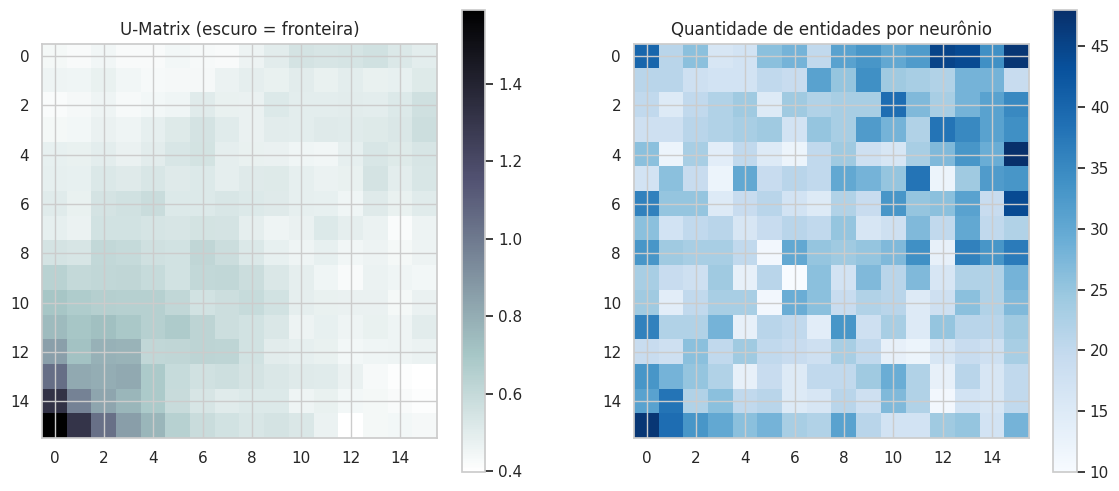

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 6))

# U-Matrix
img = eixos[0].imshow(som.u_matrix(), cmap="bone_r")
eixos[0].set_title("U-Matrix (escuro = fronteira)")
plt.colorbar(img, ax=eixos[0])

# Ocupação de cada neurônio
ocupacao = np.bincount(bmu_entidade, minlength=16 * 16).reshape(16, 16)
img = eixos[1].imshow(ocupacao, cmap="Blues")
eixos[1].set_title("Quantidade de entidades por neurônio")
plt.colorbar(img, ax=eixos[1])
plt.show()

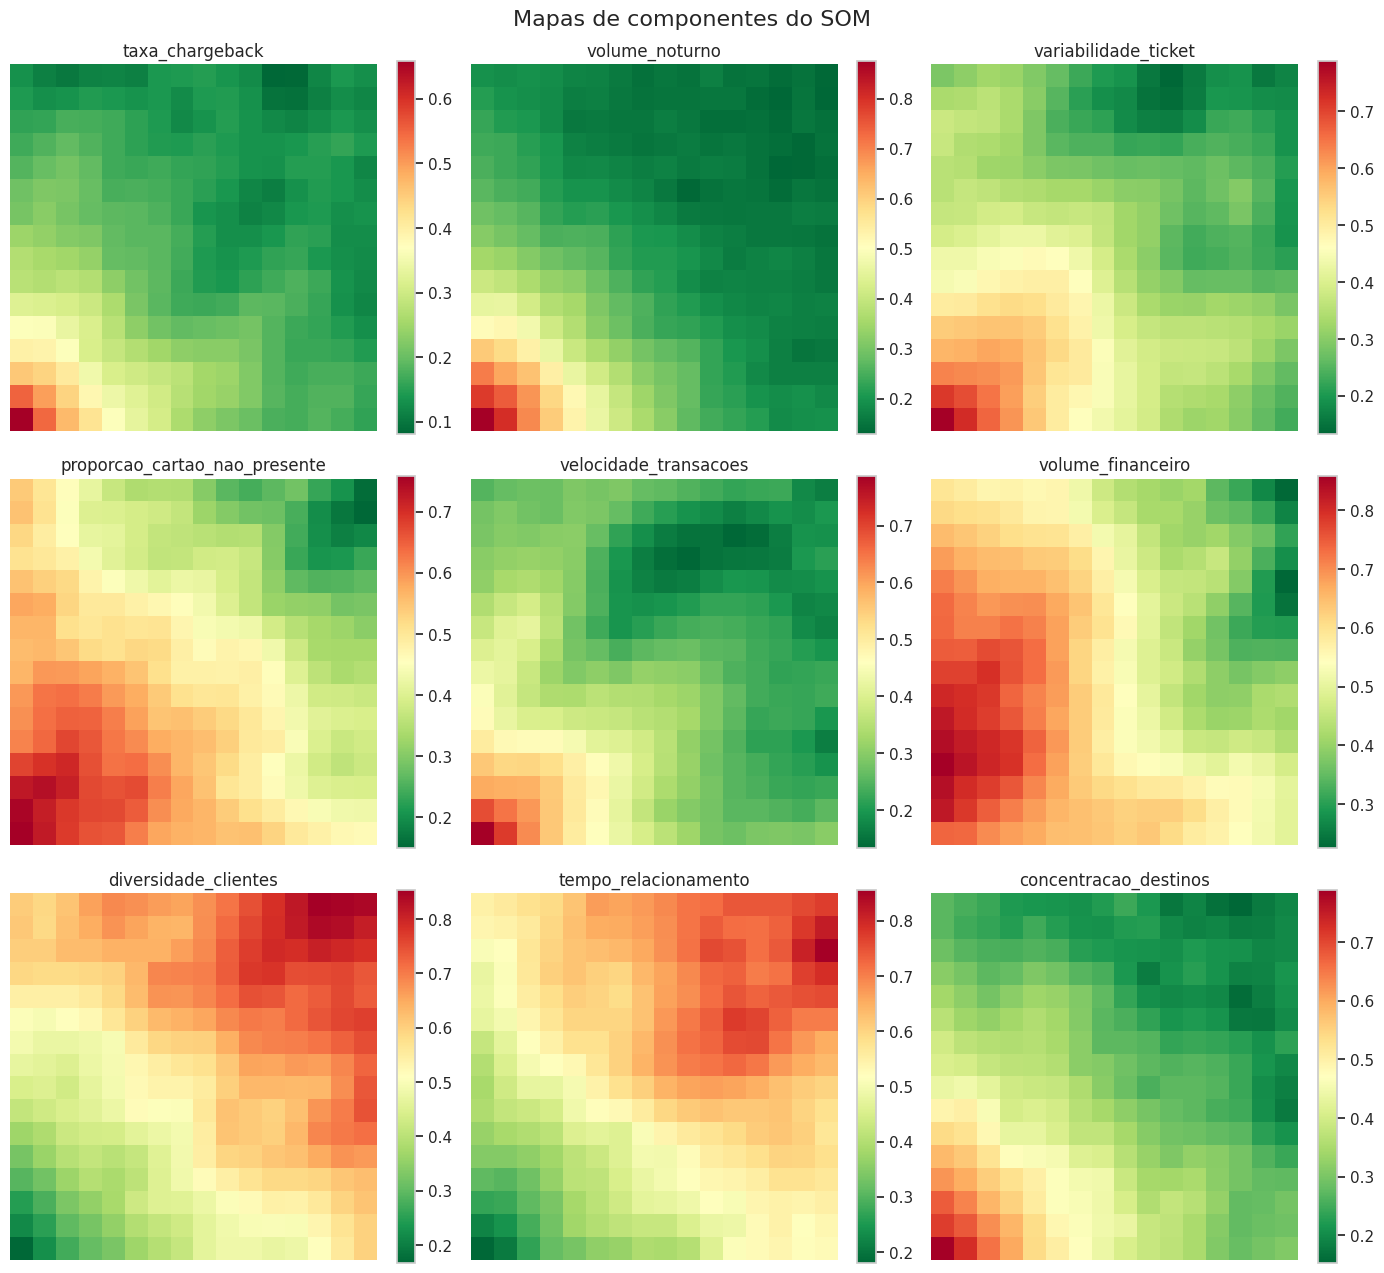

In [ ]:
# Mapas de componentes: pesos convertidos de volta para a escala original (0 a 1)
pesos_originais = scaler.inverse_transform(som.pesos)

fig, eixos = plt.subplots(3, 3, figsize=(14, 13))
for k, (eixo, coluna) in enumerate(zip(eixos.flatten(), colunas_numericas)):
    img = eixo.imshow(pesos_originais[:, k].reshape(16, 16), cmap="RdYlGn_r")
    eixo.set_title(coluna)
    eixo.axis("off")
    plt.colorbar(img, ax=eixo, fraction=0.046)
plt.suptitle("Mapas de componentes do SOM", fontsize=16)
plt.tight_layout()
plt.show()

**Leitura dos mapas de componentes:** todas as variáveis de risco ficam “quentes” (vermelho) **na mesma região do mapa**, e `diversidade_clientes`/`tempo_relacionamento` ficam baixas nessa mesma região (lembrando que para estas duas o vermelho indica valor **alto**, então o padrão aparece invertido). O SOM “desenrolou” o gradiente de risco em um **mapa 2D**: um canto concentra as entidades seguras e o canto oposto as de alto risco.

### 10.4 Agrupando os neurônios do SOM (abordagem em dois níveis)

Para obter perfis, aplicamos o **K-Means com K = 3 sobre os 256 neurônios** (e não sobre as 6000 entidades). Cada entidade herda o grupo do seu BMU.

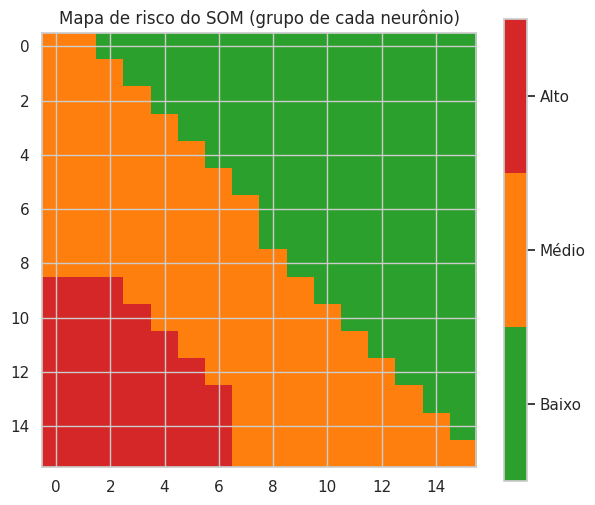

Baixo risco    2904
Médio risco    2153
Alto risco      943
Name: count, dtype: int64


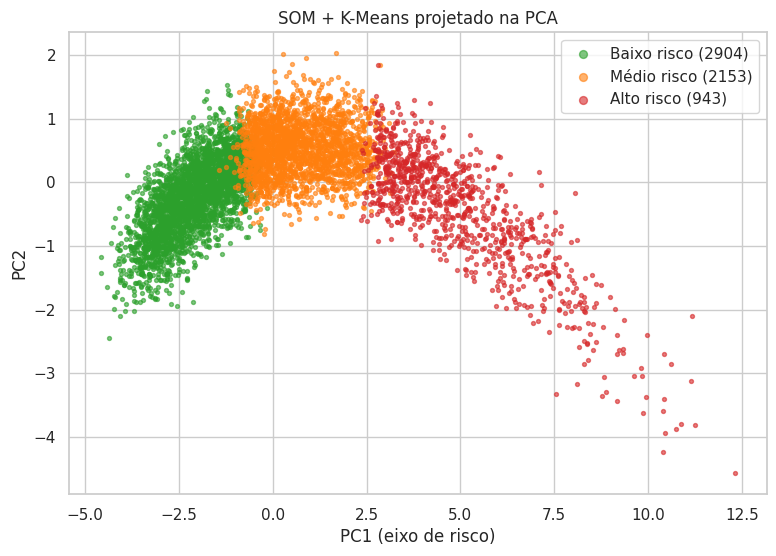

In [ ]:
# K-Means sobre os pesos dos neurônios
km_neuronios = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(som.pesos)
grupo_neuronio = km_neuronios.labels_

# Cada entidade recebe o grupo do seu neurônio vencedor
rotulos_som = ordenar_por_risco(grupo_neuronio[bmu_entidade])
df["grupo_som"] = rotulos_som
resultados.append(metricas(X_pad, rotulos_som, "SOM 16x16 + K-Means"))

# "Mapa de risco": grupo de cada neurônio desenhado na grade
grupo_neuronio_ordenado = np.zeros(256, dtype=int)
for neuronio in range(256):
    entidades = rotulos_som[bmu_entidade == neuronio]
    if len(entidades) > 0:
        grupo_neuronio_ordenado[neuronio] = np.bincount(entidades).argmax()
    else:
        # neurônio vazio (nenhuma entidade caiu nele): fica em branco no mapa
        grupo_neuronio_ordenado[neuronio] = -1

mapa = np.ma.masked_equal(grupo_neuronio_ordenado.reshape(16, 16), -1)
plt.figure(figsize=(7, 6))
cores_mapa = ListedColormap(["tab:green", "tab:orange", "tab:red"])   # baixo, médio, alto
img = plt.imshow(mapa, cmap=cores_mapa, vmin=-0.5, vmax=2.5)
barra = plt.colorbar(img, ticks=[0, 1, 2])
barra.ax.set_yticklabels(["Baixo", "Médio", "Alto"])
plt.title("Mapa de risco do SOM (grupo de cada neurônio)")
plt.show()

print(pd.Series(rotulos_som).map(NOMES_RISCO).value_counts())
grafico_pca(rotulos_som, "SOM + K-Means projetado na PCA", NOMES_RISCO)

### 10.5 Anomalias pelo SOM

Uma entidade é suspeita quando está **longe até do neurônio mais parecido** (erro de quantização individual alto). Marcamos os **2% com maior erro**.

In [ ]:
erro_individual = np.linalg.norm(X_pad - som.pesos[bmu_entidade], axis=1)
df["anomalia_som"] = erro_individual > np.percentile(erro_individual, 98)
print("Anomalias pelo SOM:", df["anomalia_som"].sum())

df.groupby("anomalia_som")[colunas_numericas].mean().T.rename(columns={False: "normal", True: "anomalia"})

Anomalias pelo SOM: 120


anomalia_som,normal,anomalia
taxa_chargeback,0.195,0.344
volume_noturno,0.248,0.438
variabilidade_ticket,0.343,0.481
proporcao_cartao_nao_presente,0.454,0.521
velocidade_transacoes,0.298,0.449
volume_financeiro,0.547,0.598
diversidade_clientes,0.586,0.464
tempo_relacionamento,0.572,0.442
concentracao_destinos,0.320,0.458


---
## 11. Comparação e validação dos modelos

### 11.1 Métricas internas

In [ ]:
tabela_metricas = pd.DataFrame(resultados).set_index("modelo")
tabela_metricas

,n_grupos,silhueta,davies_bouldin,dunn
modelo,,,,
K-Means (K=3),3,0.378,0.885,0.023
"GMM (K=3, full)",3,0.350,0.927,0.024
SOM 16x16 + K-Means,3,0.360,0.920,0.029


* Os três métodos que geram perfis (K-Means, GMM, SOM) têm métricas **parecidas e moderadas** (silhueta ≈ 0,3–0,4). Valores moderados são **esperados** em uma base contínua: não existe uma “fronteira vazia” entre os perfis.
* O **K-Means** vence nas métricas internas — o que é natural, pois silhueta e Davies-Bouldin favorecem grupos esféricos, exatamente o que o K-Means produz.
* O **Índice de Dunn** ficou **muito baixo** nos três métodos (entre 0,023 e 0,029). Isso também é esperado no gradiente contínuo: como os perfis "encostam" um no outro, a **menor distância entre grupos vizinhos é quase zero**, enquanto o **diâmetro** do grupo de alto risco é grande por causa dos pontos extremos da cauda. O Dunn é muito sensível a esses dois extremos, por isso serve mais para **confirmar a ausência de separação clara** do que para escolher um vencedor. O SOM teve o maior valor (0,029), mas a diferença entre os métodos é pequena.
* O **GMM** tem a vantagem de ser escolhido pelo **BIC** e de fornecer **probabilidades**; o **SOM**, de gerar o **mapa interpretável**.

### 11.2 Concordância entre os métodos (ARI)

Sem rótulos verdadeiros, uma forma de validar é verificar se **métodos diferentes chegam a resultados parecidos**. O **ARI (Adjusted Rand Index)** vale 1 quando dois agrupamentos são idênticos e ~0 quando a concordância é aleatória.

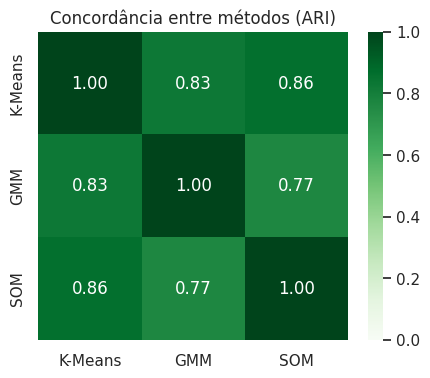

In [ ]:
agrupamentos = {"K-Means": rotulos_kmeans, "GMM": rotulos_gmm, "SOM": rotulos_som}
nomes = list(agrupamentos)
matriz_ari = pd.DataFrame(index=nomes, columns=nomes, dtype=float)
for a in nomes:
    for b in nomes:
        matriz_ari.loc[a, b] = adjusted_rand_score(agrupamentos[a], agrupamentos[b])

plt.figure(figsize=(5, 4))
sns.heatmap(matriz_ari, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1)
plt.title("Concordância entre métodos (ARI)")
plt.show()

Os ARIs entre K-Means, GMM e SOM ficam entre **≈ 0,77 e 0,86**: três algoritmos de famílias diferentes chegam a **perfis muito parecidos**. As diferenças acontecem nas **fronteiras** entre os perfis — justamente onde o GMM mostrou baixa certeza, o que é natural em um gradiente contínuo.

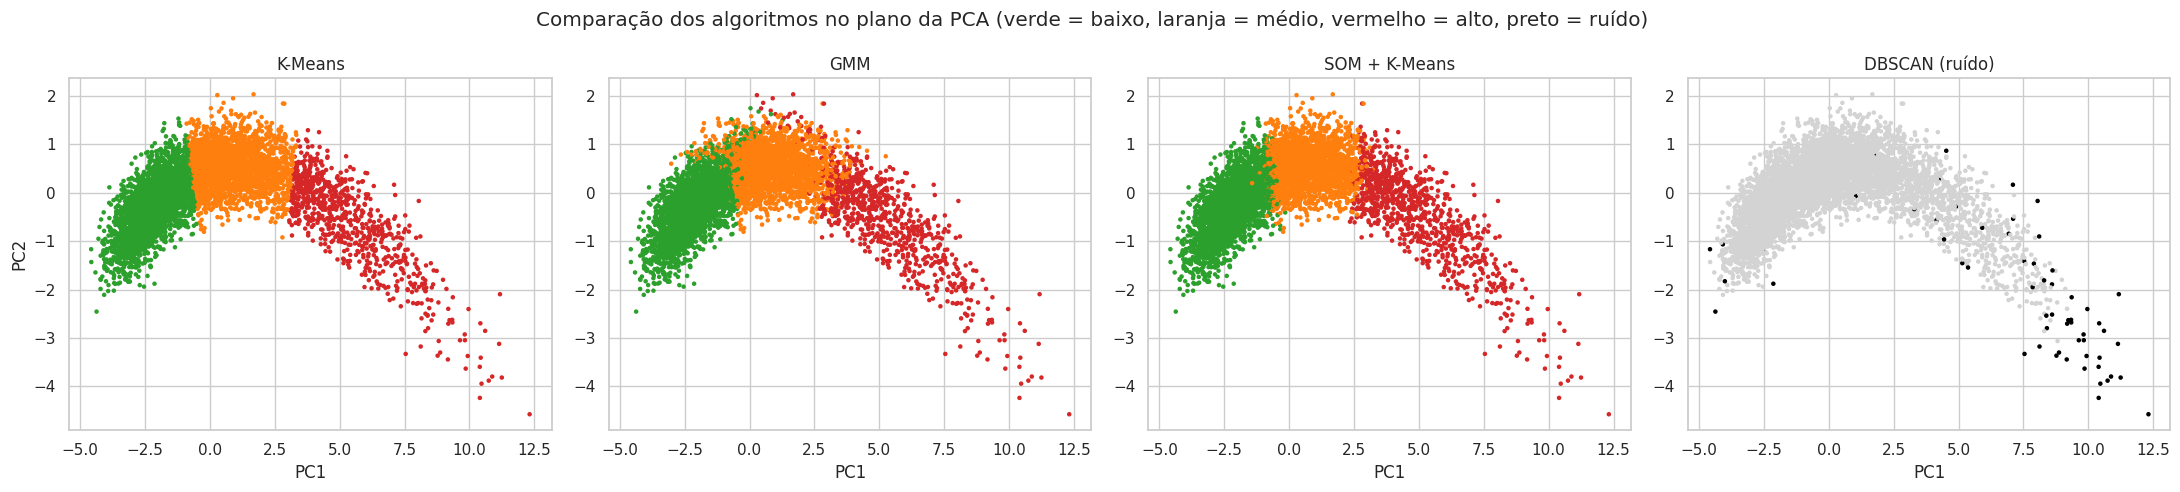

In [ ]:
# Gráficos lado a lado
fig, eixos = plt.subplots(1, 4, figsize=(22, 5))
cores = {-1: "black", 0: "tab:green", 1: "tab:orange", 2: "tab:red"}

for eixo, (titulo, rot) in zip(eixos, [("K-Means", rotulos_kmeans), ("GMM", rotulos_gmm),
                                       ("SOM + K-Means", rotulos_som), ("DBSCAN (ruído)", rotulos_dbscan)]):
    if titulo.startswith("DBSCAN"):
        cor = np.where(rot == -1, "black", "lightgray")
    else:
        cor = [cores[r] for r in rot]
    eixo.scatter(X_pca[:, 0], X_pca[:, 1], c=cor, s=5)
    eixo.set_title(titulo)
    eixo.set_xlabel("PC1")
eixos[0].set_ylabel("PC2")
plt.suptitle("Comparação dos algoritmos no plano da PCA (verde = baixo, laranja = médio, vermelho = alto, preto = ruído)")
plt.tight_layout()
plt.show()

### 11.3 Concordância na detecção de anomalias

Três métodos apontaram entidades suspeitas: **ruído do DBSCAN**, **baixa verossimilhança no GMM** e **alto erro no SOM**. Quanto mais métodos concordam, mais forte é o alerta.

votos_anomalia
0    5833
1      71
2      59
3      37
Name: count, dtype: int64


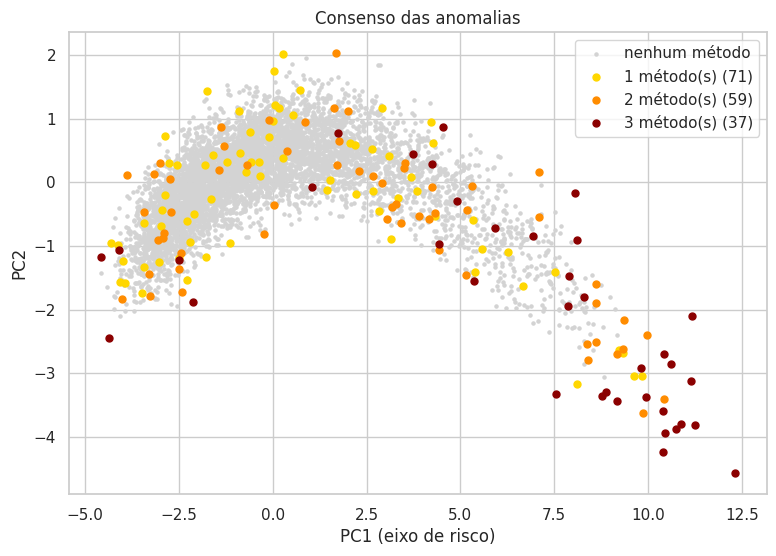

In [ ]:
# Quantos métodos marcaram cada entidade como suspeita (0 a 3)
df["votos_anomalia"] = (df["ruido_dbscan"].astype(int)
                        + df["anomalia_gmm"].astype(int)
                        + df["anomalia_som"].astype(int))
print(df["votos_anomalia"].value_counts().sort_index())

plt.figure(figsize=(9, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c="lightgray", s=5, label="nenhum método")
for votos, cor in [(1, "gold"), (2, "darkorange"), (3, "darkred")]:
    m = df["votos_anomalia"] == votos
    plt.scatter(X_pca[m, 0], X_pca[m, 1], c=cor, s=25, label=f"{votos} método(s) ({m.sum()})")
plt.legend()
plt.xlabel("PC1 (eixo de risco)"); plt.ylabel("PC2")
plt.title("Consenso das anomalias")
plt.show()

**Leitura:** as entidades marcadas por **2 ou 3 métodos** concentram-se principalmente na **cauda direita** (alto risco). Algumas aparecem também no meio ou à esquerda da nuvem: são entidades com **combinações incomuns** de variáveis (ex.: chargeback alto mas conta antiga), que também merecem uma checagem.

---
## 12. Mapa de risco final e recomendações de negócio

Combinamos os resultados em uma **classificação de alerta** para cada entidade:

| Nível | Regra | Ação sugerida |
|---|---|---|
| 🔴 **Crítico** | marcada como anomalia por **2 ou 3 métodos** | bloqueio preventivo e análise manual imediata |
| 🟠 **Alto** | perfil de **alto risco** no GMM (ou 1 voto de anomalia) | monitoramento reforçado, limites menores, autenticação extra (3DS) |
| 🟡 **Médio** | perfil de **médio risco** | regras automáticas de alerta em transações noturnas/online |
| 🟢 **Baixo** | perfil de **baixo risco** | fluxo normal, menos atrito para o cliente |

In [ ]:
def nivel_alerta(linha):
    # Define o nível de alerta combinando o perfil do GMM e os votos de anomalia
    if linha["votos_anomalia"] >= 2:
        return "1-Crítico"
    if linha["grupo_gmm"] == 2 or linha["votos_anomalia"] == 1:
        return "2-Alto"
    if linha["grupo_gmm"] == 1:
        return "3-Médio"
    return "4-Baixo"

df["nivel_alerta"] = df.apply(nivel_alerta, axis=1)

# Quantidade e percentual de entidades em cada nível
resumo = df["nivel_alerta"].value_counts().sort_index().to_frame("entidades")
resumo["percentual"] = resumo["entidades"] / len(df)
resumo

,entidades,percentual
nivel_alerta,,
1-Crítico,96,0.016
2-Alto,804,0.134
3-Médio,2245,0.374
4-Baixo,2855,0.476


In [ ]:
# Perfil médio de cada nível de alerta (escala original 0 a 1)
perfil_final = df.groupby("nivel_alerta")[colunas_numericas].mean().T
perfil_final

nivel_alerta,1-Crítico,2-Alto,3-Médio,4-Baixo
taxa_chargeback,0.407,0.374,0.204,0.137
volume_noturno,0.520,0.551,0.249,0.160
variabilidade_ticket,0.548,0.570,0.389,0.241
proporcao_cartao_nao_presente,0.575,0.654,0.523,0.343
velocidade_transacoes,0.518,0.522,0.325,0.212
volume_financeiro,0.629,0.748,0.636,0.419
diversidade_clientes,0.402,0.351,0.520,0.705
tempo_relacionamento,0.376,0.343,0.515,0.682
concentracao_destinos,0.527,0.559,0.357,0.223


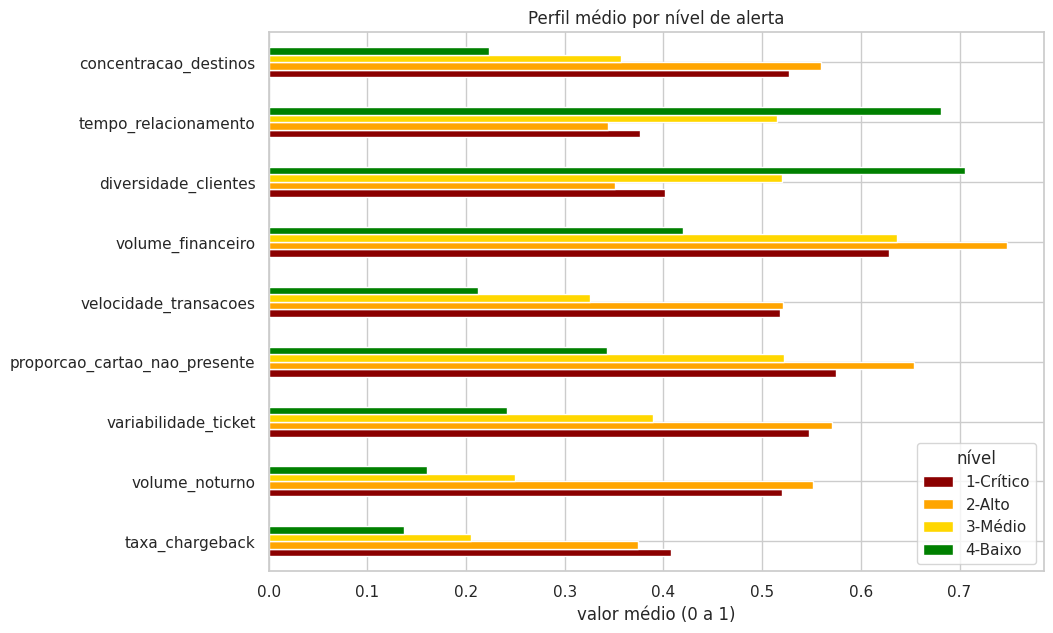

tipo_entidade,lojista,portador
nivel_alerta,,
1-Crítico,0.018,0.015
2-Alto,0.132,0.135
3-Médio,0.387,0.368
4-Baixo,0.463,0.482


In [ ]:
# Gráfico de "radar simplificado": barras do perfil de cada nível
perfil_final.plot(kind="barh", figsize=(10, 7), color=["darkred", "orange", "gold", "green"])
plt.title("Perfil médio por nível de alerta")
plt.xlabel("valor médio (0 a 1)")
plt.legend(title="nível")
plt.show()

# Lojistas x portadores em cada nível
pd.crosstab(df["nivel_alerta"], df["tipo_entidade"], normalize="columns").round(3)

In [ ]:
# Lista das 15 entidades mais suspeitas
colunas_relatorio = ["id_entidade", "tipo_entidade", "nivel_alerta", "votos_anomalia",
                     "taxa_chargeback", "volume_noturno", "velocidade_transacoes",
                     "concentracao_destinos", "tempo_relacionamento"]
(df[df["nivel_alerta"] == "1-Crítico"]
   .sort_values(["votos_anomalia", "taxa_chargeback"], ascending=False)[colunas_relatorio]
   .head(15))

,id_entidade,tipo_entidade,nivel_alerta,votos_anomalia,taxa_chargeback,volume_noturno,velocidade_transacoes,concentracao_destinos,tempo_relacionamento
2303,E002304,portador,1-Crítico,3,1.000,1.000,0.956,0.984,0.021
1980,E001981,lojista,1-Crítico,3,0.904,0.959,1.000,0.856,0.034
1958,E001959,portador,1-Crítico,3,0.853,0.937,0.842,0.901,0.209
529,E000530,portador,1-Crítico,3,0.851,0.980,0.848,0.887,0.046
46,E000047,portador,1-Crítico,3,0.825,0.982,0.911,0.926,0.178
4600,E004601,portador,1-Crítico,3,0.812,0.912,0.849,0.855,0.085
1096,E001097,lojista,1-Crítico,3,0.799,0.993,0.979,0.929,0.162
5420,E005421,lojista,1-Crítico,3,0.790,0.980,0.871,0.959,0.134
4465,E004466,portador,1-Crítico,3,0.786,0.966,0.915,0.914,0.049
4119,E004120,lojista,1-Crítico,3,0.749,0.919,0.931,0.823,0.083


In [ ]:
# Salva o resultado final
df.to_csv("resultado_mapa_risco.csv", index=False)
print("Arquivo 'resultado_mapa_risco.csv' salvo com", len(df), "linhas.")

Arquivo 'resultado_mapa_risco.csv' salvo com 6000 linhas.


---
## 13. Conclusões

### Achados técnicos

1. **Diagnóstico da base 05:** dados limpos (sem ausentes/duplicados), já normalizados em [0,1], com variáveis **muito correlacionadas**. A PCA mostra que **um único eixo explica ~82% da variância** → a base é um **gradiente contínuo de risco**, com uma **cauda de entidades extremas**.
2. **K-Means e GMM** concordaram em **3 perfis** (baixo, médio e alto risco). O K = 3 foi apoiado pelo metodo do cotovelo, pelo **BIC do GMM** e pelo contexto do negócio.
3. O **DBSCAN** encontrou só **um núcleo denso**, confirmando a ausência de grupos separados, e foi usado como **detector de ruído**: os pontos de ruído estão na ponta de maior risco.
4. O **SOM** transformou o gradiente em um **mapa 2D interpretável**; os mapas de componentes mostram que chargeback, volume noturno, velocidade e concentração de destinos crescem juntos, enquanto tempo de relacionamento e diversidade de clientes diminuem.
5. A **concordância alta entre métodos (ARI)** e o **consenso das anomalias** aumentam a confiança nos resultados, mesmo sem rótulos.

### Ações práticas contra fraude

* **Fila de investigação prioritária:** as entidades de nível **Crítico** (consenso de 2–3 métodos, cerca de **1,6% da base ≈ 96 entidades**) devem ser analisadas primeiro — é um grupo pequeno, o que torna a revisão manual viável.
* **Regras de monitoramento:** o perfil de alto risco combina **chargeback alto + transações noturnas + cartão não presente + alta velocidade + poucos destinos**. Essas variáveis podem virar **regras em tempo real** (ex.: alerta quando uma conta nova faz muitas transações online de madrugada).
* **Atenção a contas novas:** baixo `tempo_relacionamento` aparece forte no perfil de risco → aplicar **limites progressivos** para novos lojistas/portadores.
* **Menos atrito para os bons clientes:** o grupo de baixo risco (maior parte da base) pode ter **menos autenticações extras**, melhorando a experiência.
* **Rótulos futuros:** as entidades investigadas geram **rótulos reais de fraude**, que permitirão, no futuro, treinar modelos supervisionados e calibrar os cortes de 2% usados aqui.

### Limitações

* Sem rótulos verdadeiros, não é possível medir acerto (precisão/recall) — apenas coerência interna e concordância entre métodos.
* Os cortes de anomalia (2%) e o `eps` do DBSCAN são escolhas que devem ser **ajustadas com a área de negócio** conforme a capacidade de investigação.